# Feature Selection & Dimensionality Reduction: In Situ Imaging Transcriptomics (10x Xenium)

## Introduction

Having executed multi-factorial morphological quality control ([notebook 06](./06-quality_control_Xenium_imaging.ipynb)) and size-factor log-normalization ([notebook 09](./09-normalization_Xenium_imaging.ipynb)), we now adapt the intermediate-processing framework developed for Visium HD segmented cells ([notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb)) and 16-µm bins ([notebook 11](./11-feature_selection_dimensionality_reduction_VisiumHD_binned.ipynb)) to **subcellular imaging transcriptomics (10x Xenium)**.

Transitioning from unbiased whole-transcriptome capture (≈ 18,000 genes) to a targeted 515-feature padlock-probe panel across **47,671 single cells** fundamentally changes the statistical assumptions at every step of the workflow:

1. **No HVG Truncation (Curated Panel Retention):** In whole-transcriptome Visium HD, over 90% of measured genes are _invariant housekeeping transcripts or low-count Poisson shot noise_, making top-1,000 HVG selection essential. In Xenium, **feature selection was performed *a priori* during panel design**: all **422 targeted biological genes** represent curated lineage, stromal, vascular, and immune markers. Truncating this panel would discard definitive markers of rarer single-cell populations. Instead, our primary filtering responsibility is isolating the 422 biological targets from the **93 active negative control probes and codewords** retained in [notebook 06](./06-quality_control_Xenium_imaging.ipynb) before running dimensionality reduction.
2. **Full-Panel Spatial Autocorrelation as a Ranking System:** Because the curated biological panel spans just 422 genes, computing graph-based Moran's $I$ across **every single feature on the panel** ($P = 515$) is computationally rapid even across 47,671 cells. Rather than discarding low-autocorrelation genes as noise, full-panel Moran's $I$ serves as a **spatial ranking system** that separates macro-compartment architectural drivers from dispersed, cell-autonomous functional states (e.g., proliferating cells, infiltrating T cells, and mast cells).
3. **Standard PCA on the Complete Curated Panel:** Computing Principal Component Analysis (PCA) directly across all 422 biological genes avoids arbitrary variance cutoffs while maximizing lineage resolution across colorectal adenocarcinoma microenvironments.
4. **Dual-Regime BANKSY at True Single-Cell Resolution:** Unlike 16-µm binned grids—where physical bin averaging inherently blurs co-resident cells—Xenium's diffraction-limited subcellular localization lets **BANKSY** thrive across two complementary analytical regimes using the same spatial neighborhood graph: **low neighborhood mixing (λ = 0.2)** for noise-regularized **cell-type assignment**, and **high neighborhood mixing (λ = 0.8)** for continuous **tissue domain segmentation**, where neighborhood identity compensates for the 422-gene panel limit by grouping cells according to their local histological niche.

## Learning objectives

* Contrast raw-count $\log_{10}$–$\log_{10}$ Poisson–Negative Binomial modeling ([notebook 06](./06-quality_control_Xenium_imaging.ipynb)) with log-normalized `scran::modelGeneVarByPoisson()` variance decomposition, explaining why HVG truncation is skipped in curated Xenium panels while negative control probes must be masked.
* Compute and rank **Moran's $I$ across all 422 biological genes** (and 93 active negative controls), distinguishing macro-compartment drivers, focal vascular/proliferative markers, and dispersed cell-autonomous markers, alongside multi-scale `nnSVG` validation.
* Execute standard PCA directly on all 422 curated biological genes and link eigenvector loadings to colorectal mucosal, neoplastic, and stromal lineages.
* Implement **dual-regime BANKSY** (`lambda = c(0.2, 0.8)` at `k_geom = 20`) to compare **single-cell typing (λ = 0.2)** against **tissue domain segmentation (λ = 0.8)** across spatial PC maps and three-way UMAP manifolds.

## Environment setup

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial & Bioconductor containers
  library(SpatialFeatureExperiment)
  library(Voyager)
  library(alabaster.sfe)

  # Single-cell statistics & dimensionality reduction
  library(scran)
  library(scater)

  # Spatially-aware dimensionality reduction
  library(Banksy)

  # Visualization, palettes & layouts
  library(ggplot2)
  library(patchwork)
  library(pals)
}))

# Enforce global reproducibility for stochastic algorithms (PCA, UMAP, nnSVG)
set.seed(42)

### Restoring the normalized Xenium dataset

We restore the normalized `SpatialFeatureExperiment` (`sfe`) container serialized at the end of [notebook 09](./09-normalization_Xenium_imaging.ipynb) and ensure both `counts` and `logcounts` reside in standard in-memory sparse `dgCMatrix` representation for fast downstream matrix operations across C++ kernels.

In [2]:
# Define path to the normalized Xenium object from notebook 09
sfe_path <- "output/sfe_xenium_normalized"

# Restore the SFE object using alabaster serialization
sfe <- readObject(sfe_path)

# Cast ReloadedMatrix assays to standard in-memory dgCMatrix
counts(sfe) <- as(counts(sfe), "dgCMatrix")
logcounts(sfe) <- as(logcounts(sfe), "dgCMatrix")

# Verify dimensions, assays, colData, and spatial geometries
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 515 47671 
metadata(1): Samples
assays(2): counts logcounts
rownames(515): ABCC8 ACP5 ... UnassignedCodeword_0292
  UnassignedCodeword_0298
rowData names(10): ID Symbol ... vars is_neg
colnames(47671): ablhnkec-1 ablhpkkh-1 ... oikdllpb-1 oikeebja-1
colData names(40): transcript_counts control_probe_counts ... qc_keep
  sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : x_centroid y_centroid
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (MULTIPOLYGON), nucSeg (MULTIPOLYGON) 

Graphs:
sample01: 

The restored `sfe` container comprises **47,671 high-confidence single cells** and **515 active features** across `counts` and `logcounts`, paired with `centroids`, `cellSeg`, and `nucSeg` polygon geometries in micron units. Notice that `reducedDimNames(sfe)` is currently empty (`0`).

## Feature variance & curated panel masking

### Separating biological targets from negative controls

Before quantifying feature variance or computing embeddings, we explicitly distinguish our **422 endogenous biological targets** from the **93 active negative control probes and codewords** preserved in `rowData(sfe)[["is_neg"]]`.

We deliberately retained those 93 active controls during QC ([notebook 06](./06-quality_control_Xenium_imaging.ipynb)) and normalization ([notebook 09](./09-normalization_Xenium_imaging.ipynb)) so that downstream spatial modeling, false-discovery benchmarking, and cell-type deconvolution algorithms can reference an _empirical optical background floor_. However, dimensionality reduction (PCA and BANKSY) must operate exclusively on genuine biological transcription so technical probes cannot influence latent embeddings.

In [3]:
rowData(sfe) |> names()

[1] "ID"                  "Symbol"              "Type"               
 [4] "subsets_negProbe"    "subsets_negCodeword" "subsets_unassigned" 
 [7] "subsets_any_neg"     "means"               "vars"               
[10] "is_neg"

In [4]:
# Register an explicit logical mask for curated biological targets (excluding negative controls)
rowData(sfe)[["is_bio"]] <- !rowData(sfe)[["is_neg"]]

# Verify exact feature counts across biological genes and negative control categories
table(
  Biological_Gene = rowData(sfe)[["is_bio"]],
  Feature_Type    = rowData(sfe)[["Type"]]
)

               Feature_Type
Biological_Gene Gene Expression Negative Control Codeword
          FALSE               0                        30
          TRUE              422                         0
               Feature_Type
Biological_Gene Negative Control Probe Unassigned Codeword
          FALSE                     20                  43
          TRUE                       0                   0

The cross-tabulation confirms that `is_bio` cleanly isolates all **422 `Gene Expression` targets** while flagging the **93 non-biological technical controls** (30 negative control codewords, 20 negative control probes, and 43 unassigned codewords).

### Mean–variance modeling in `logcounts` vs. Notebook 06 raw counts

In [notebook 06](./06-quality_control_Xenium_imaging.ipynb), we evaluated gene overdispersion on **raw molecular counts** ($Y_{gi}$) using $\log_{10}$–$\log_{10}$ axes (`means` vs. `vars`), where pure Poisson background forms a straight $45^\circ$ diagonal ($y = x$) and biological markers diverge upward along a quadratic Negative Binomial curve ($\operatorname{Var}(Y_g) = \mu_g + \alpha_g \mu_g^2$).

Here, `scran::modelGeneVarByPoisson()` operates on **size-factor normalized `logcounts`** ($Y'_{gi} = \log_2(X_{gi}/s_i + 1)$) plotted on **linear axes**, producing a fundamentally different visual geometry:

* **Variance Stabilization at High Expression:** Log-transformation compresses large count fluctuations ($\operatorname{Var}(\log(Y + 1)) \approx \frac{\operatorname{Var}(Y)}{(\mu + 1)^2}$), bending the linear Poisson identity line into a concave curve that gradually plateaus around $\sigma^2_{\text{tech}} \approx 0.75\text{–}0.80$ at mean `logcounts` near 1.0–1.1.
* **Empirical Noise Floor vs. Curated Panel Signal:** Plotting both the 422 biological genes and the 93 active negative controls against this fitted Poisson trend lets us test directly in `logcounts` space whether the curated panel exhibits excess biological variance across its targets.

In [5]:
# Decompose total vs. Poisson technical variance in normalized logcounts across all 515 features
gene_var <- modelGeneVarByPoisson(sfe, assay.type = "logcounts")
rowData(sfe)[["bio"]] <- gene_var[["bio"]]

Warning message in .model_gene_var_by_poisson(assay(x, i = assay.type), ...):
"'modelGeneCV2ByPoisson' est obsolète.
Voir help("Deprecated")"
Warning message in fitTrendVar(fm, fv, ...):
"'fitTrendVar' est obsolète.
Utilisez plutôt ‘scrapper::fitVarianceTrend’.
Voir help("Deprecated")"
Warning message in combineBlocks(collected, method = method, equiweight = equiweight, :
"'combineBlocks' est obsolète.
Voir help("Deprecated")"


In [6]:
# Compare residual biological variance between curated genes and active negative controls
is_bio <- rowData(sfe)[["is_bio"]]
cat("Biological genes (n = 422):")
summary(rowData(sfe)[is_bio, "bio"])

cat("Active negative controls (n = 93):")
summary(rowData(sfe)[!is_bio, "bio"])

Biological genes (n = 422):

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
0.0005611 0.0162301 0.0461534 0.0954239 0.1248269 0.8261877 

Active negative controls (n = 93):

      Min.    1st Qu.     Median       Mean    3rd Qu.       Max. 
-2.735e-05 -5.138e-06  6.860e-06  1.519e-04  5.395e-05  9.379e-03 

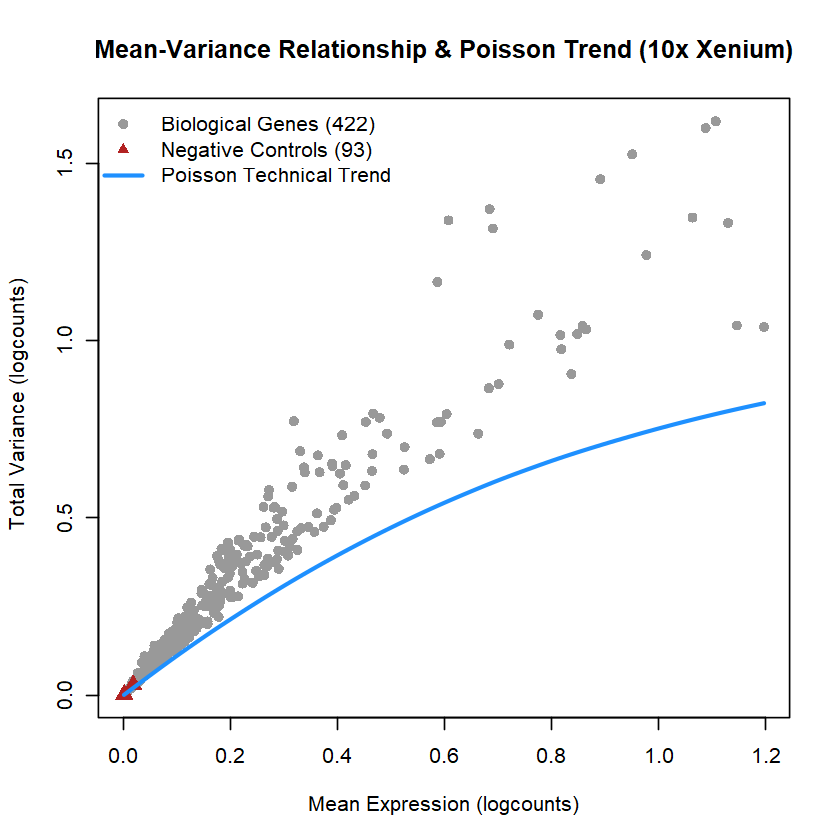

In [7]:
# Scatter plot: Total observed variance vs. mean logcounts across all 515 features
plot(
  x = gene_var[["mean"]][is_bio], 
  y = gene_var[["total"]][is_bio], 
  pch = 16, 
  col = "gray60", 
  xlab = "Mean Expression (logcounts)", 
  ylab = "Total Variance (logcounts)", 
  main = "Mean-Variance Relationship & Poisson Trend (10x Xenium)"
)

# Highlight the 93 active negative controls clustered near the origin
points(
  x = gene_var[["mean"]][!is_bio], 
  y = gene_var[["total"]][!is_bio], 
  pch = 17, 
  cex = 1.5, 
  col = "firebrick"
)

# Overlay fitted technical trend stored in metadata(gene_var)[["trend"]]
curve(
  metadata(gene_var)[["trend"]](x), 
  add = TRUE, 
  col = "dodgerblue", 
  lwd = 2.5
)

legend(
  "topleft",
  legend = c(
    "Biological Genes (422)", 
    "Negative Controls (93)", 
    "Poisson Technical Trend"), 
  col    = c("gray60", "firebrick", "dodgerblue"), 
  pch    = c(16, 17, NA), 
  lty    = c(NA, NA, 1), 
  lwd    = c(NA, NA, 2.5), 
  bty    = "n"
)

Because non-specific probe binding and optical misdecoding average well below 0.02 raw UMIs/cell, all 93 negative controls collapse onto a single tight cluster at the `(0, 0)` origin directly along the blue Poisson curve (`bio` Median = 0.0000069, Mean = 0.000152, interquartile range [-0.0000051, 0.0000540]). Unlike the $\log_{10}$–$\log_{10}$ raw-count view in Notebook 06—which spreads those ultra-low means across four orders of magnitude ($10^{-5}$ to $10^{-2}$)—linear `logcounts` axes compress the entire technical noise floor to `(0, 0)`.

In contrast, every single biological target exhibits strictly positive excess biological variance ($\sigma^2_{\text{bio}} \ge 0.000561$, Median = 0.04615, Mean = 0.09542, Max = 0.82619), lifting visibly above the blue Poisson trend (`dodgerblue`), which levels off toward ≈ 0.80 at mean `logcounts` near 1.1–1.2, with the strongest biological drivers reaching total variances of 1.32–1.62.

Because all 422 biological targets carry genuine panel-curated signal above the Poisson technical baseline—and because no uninformative housekeeping tail exists to dilute covariance—we **skip HVG selection** and retain **100% of the 422 biological genes** (`is_bio`) for downstream PCA and BANKSY. Next, we rank the top 10 drivers of `bio` variance and visualize the top 6 across `cellSeg` polygons.

In [8]:
# Inspect the top 10 biological variance drivers across the 422-gene panel
gene_var[is_bio, ] |>
  as.data.frame() |>
  dplyr::slice_max(bio, n = 10)

,mean,total,tech,bio,p.value,FDR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
IGFBP7,1.1060527,1.619328,0.7931401,0.8261877,0,0
HLA-DRA,1.0873796,1.600271,0.7863766,0.8138940,0,0
MMP2,0.9501422,1.526413,0.7315773,0.7948360,0,0
IGHG3,0.6068508,1.339693,0.5478001,0.7918927,0,0
GREM1,0.6836251,1.371226,0.5962878,0.7749383,0,0
TAGLN,0.8906082,1.455936,0.7051894,0.7507467,0,0
PIGR,0.6895840,1.316903,0.5998870,0.7170162,0,0
PECAM1,0.5860349,1.165785,0.5339724,0.6318128,0,0
ACTA2,1.0628034,1.347734,0.7772328,0.5705016,0,0


Because canonical pan-plasma-cell `IGKC` and fibrillar collagens `COL1A1`/`COL3A1` are absent from this targeted panel, excess biological variance is led by **`IGFBP7`** (`bio` = 0.8265), **`HLA-DRA`** (`bio` = 0.8141), **`MMP2`** (`bio` = 0.7946), **`IGHG3`** (`bio` = 0.7907), **`GREM1`** (`bio` = 0.7749), and **`TAGLN`** (`bio` = 0.7507), followed by mucosal **`PIGR`** (`bio` = 0.7171), endothelial **`PECAM1`** (`bio` = 0.6306), smooth-muscle **`ACTA2`** (`bio` = 0.5706), and stromal **`THBS1`** (`bio` = 0.5316).

In [9]:
# Extract the top 6 biological variance drivers and map their normalized expression
top_bio_var <- getTopHVGs(gene_var[is_bio, ], n = 6)
top_bio_var

Warning message in getTopHVGs(gene_var[is_bio, ], n = 6):
"'getTopHVGs' est obsolète.
Utilisez plutôt ‘scrapper::chooseHighlyVariableGenes’.
Voir help("Deprecated")"


[1] "IGFBP7"  "HLA-DRA" "MMP2"    "IGHG3"   "GREM1"   "TAGLN"

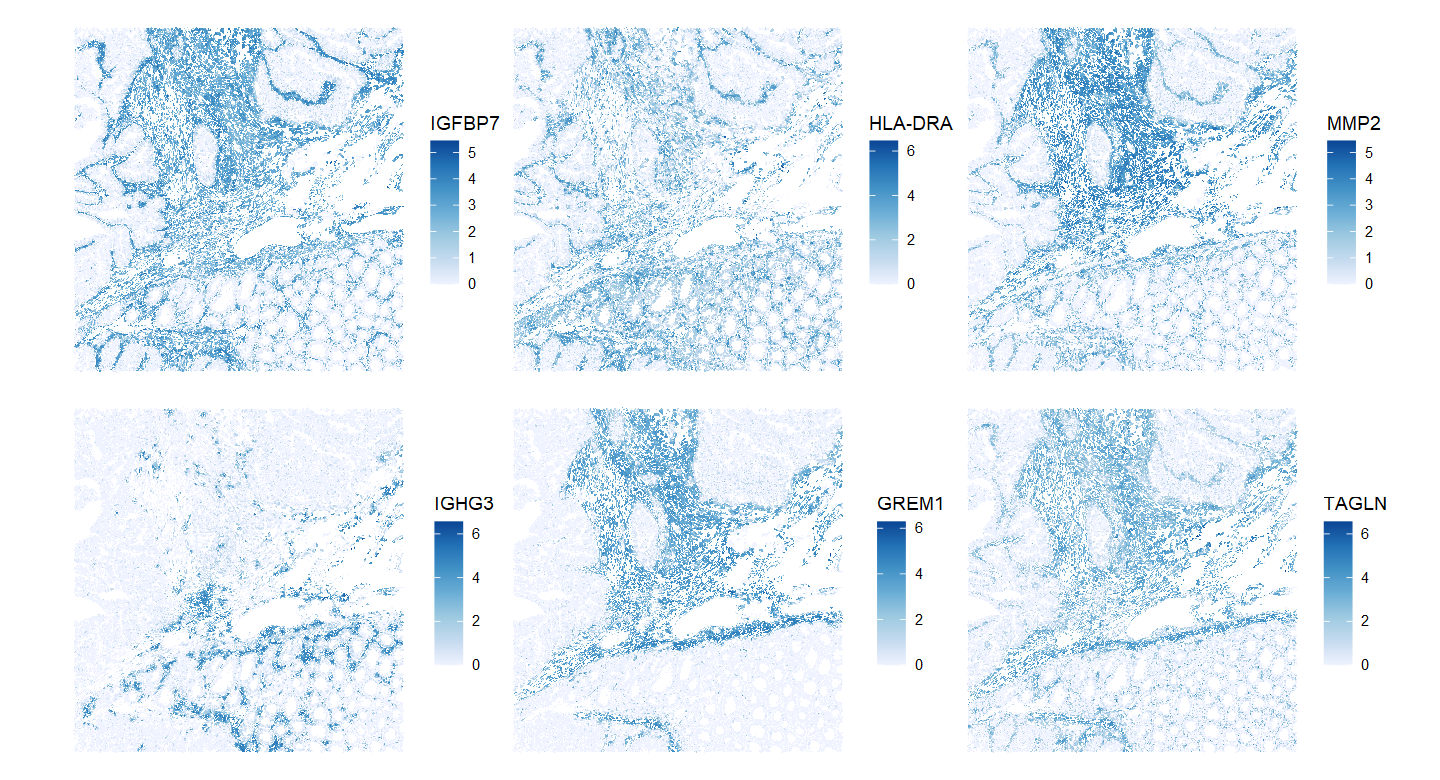

In [10]:
options(repr.plot.width = 12, repr.plot.height = 6.5)

plotSpatialFeature(
  sfe, 
  features = top_bio_var, 
  colGeometryName = "cellSeg", 
  ncol = 3
)

Projecting the top six drivers onto `cellSeg` polygons resolves Patient P2's colorectal adenocarcinoma architecture at crisp single-cell resolution, with the regular circular crypts of the **normal colonic mucosa** occupying the lower-right band and the lobulated **invasive cribriform adenocarcinoma nests** (appearing as pale, unstained epithelial silhouettes along the far-left, upper-right, and lower-left margins) embedded within a reactive **desmoplastic stroma** above the prominent horizontal void of the dilated submucosal vessel. Within this mesenchymal compartment, **`IGFBP7`** broadly illuminates both the upper desmoplastic stroma and the inter-crypt lamina propria honeycomb below, whereas **`MMP2`** concentrates more selectively within the central and upper tumor-associated stroma cradling the malignant glands. By contrast, **`GREM1`** exhibits the sharpest compartment restriction among the stromal drivers: reactive cancer-associated fibroblasts (CAFs) intensely blanket the upper peritumoral stroma and form a crisp frontier along the diagonal muscularis interface beneath the submucosal vessel, while remaining virtually silent throughout the normal mucosal lamina propria below. Flanking this same boundary, **`TAGLN`** traces the contractile smooth muscle of the muscularis mucosae, perivascular vessel walls, and stromal myofibroblasts.

Superimposed on this stromal scaffold, the two leading immune drivers occupy complementary microanatomical niches. **`HLA-DRA`** marks MHC class II-positive antigen-presenting macrophages and dendritic cells densely populating the lower mucosal lamina propria honeycomb alongside focal infiltrates within the upper tumor bed and stroma, whereas **`IGHG3`** is tightly restricted to discrete clusters of IgG-secreting plasma cells concentrated along the central invasive margin and the upper mucosal border just beneath the dilated submucosal vessel.

## Spatial autocorrelation & full-panel SVG ranking

### Full-panel Moran's $I$ across all 515 features

In whole-transcriptome Visium HD, computing Moran's $I$ across > 18,000 genes imposes substantial serial runtime overhead, so we restricted testing to a 10-gene benchmark panel. In Xenium, although cell count increases to **47,671 individual cells**, evaluating graph-based Moran's $I$ across **all 515 features** (422 biological genes plus 93 negative controls) on a $k = 6$ nearest-neighbor graph requires under a minute.

Crucially, the analytical role of Moran's $I$ shifts from *filtering* to *ranking*: rather than pruning genes with low spatial autocorrelation, we compute Moran's $I$ across the entire curated panel to discover which targets drive broad tissue architecture versus focal niches versus dispersed single-cell states.

In [11]:
# Construct a k = 6 nearest-neighbor spatial graph across all 47,671 cell centroids
colGraph(sfe, "knn6") <- findSpatialNeighbors(
  sfe, 
  method = "knearneigh", 
  k = 6, 
  zero.policy = TRUE
)

In [12]:
# Compute Moran's I across EVERY feature on the panel (422 biological + 93 controls)
sfe <- runMoransI(
  sfe, 
  features = rownames(sfe), 
  colGraphName = "knn6"
)

In [13]:
# Compare Moran's I distributions between biological genes and negative controls
cat("Moran's I — Biological genes (n = 422):\n")
summary(rowData(sfe)[is_bio, "moran_sample01"])

cat("\nMoran's I — Negative controls (n = 93):\n")
summary(rowData(sfe)[!is_bio, "moran_sample01"])

Moran's I — Biological genes (n = 422):


     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
-0.003385  0.039925  0.124090  0.169331  0.218714  0.811820 


Moran's I — Negative controls (n = 93):


      Min.    1st Qu.     Median       Mean    3rd Qu.       Max. 
-2.342e-04 -7.172e-05 -4.060e-05  1.846e-04 -2.098e-05  9.557e-03 

The 93 active negative controls exhibit Moran's $I$ centered squarely at zero (Median = -0.000041, Mean = 0.000186, Max = 0.00956), providing an independent spatial proof that optical background noise is spatially random across the tissue slide. In contrast, the 422 biological genes span a wide continuum from -0.00339 up to 0.81182 (Median = 0.12409, Mean = 0.16933, 3rd Qu. = 0.21871).

Let's inspect both extremes of the biological spatial ranking—comparing the **top 10 macro-compartment drivers** against **actively expressed (`means` ≥ 0.05 raw UMIs/cell) low-autocorrelation genes**—and visualize the panel-wide joint distribution of `bio` variance versus `moran_sample01`.

In [14]:
# Assemble a clean feature-level data frame from rowData(sfe)
df_panel <- rowData(sfe) |>
  as.data.frame() |>
  dplyr::mutate(
    gene = rownames(sfe),
    feature_class = ifelse(is_bio, "Biological Gene (422)", "Negative Control (93)")
  )

# Top 10 spatially autocorrelated panel genes
cat("Top 10 biological genes by Moran's I:\n")
df_panel |>
  dplyr::filter(is_bio) |>
  dplyr::select(bio, moran_sample01) |>
  dplyr::slice_max(moran_sample01, n = 10)

Top 10 biological genes by Moran's I:


,bio,moran_sample01
,<dbl>,<dbl>
PIGR,0.7170162,0.8118199
CEACAM6,0.3712792,0.7960755
GREM1,0.7749383,0.7628280
OLFM4,0.3013145,0.7386020
LGR5,0.2334452,0.7065247
FABP1,0.2705446,0.6814012
FERMT1,0.2328376,0.6790705
REG1A,0.1623352,0.6780896
CEACAM5,0.3057613,0.6655131


In [15]:
# Bottom 5 actively expressed biological genes (mean raw count >= 0.05) by Moran's I
cat("\nBottom 5 active biological genes (mean raw count >= 0.05) by Moran's I:\n")
df_panel |>
  dplyr::filter(is_bio, means >= 0.05) |>
  dplyr::select(means, bio, moran_sample01) |>
  dplyr::slice_min(moran_sample01, n = 5)


Bottom 5 active biological genes (mean raw count >= 0.05) by Moran's I:


,means,bio,moran_sample01
,<dbl>,<dbl>,<dbl>
SFXN1,0.18470962,0.07103857,0.01071587
HDC,0.16355647,0.08109355,0.01460201
NOSIP,0.06269855,0.02244243,0.01936123
CD8B,0.05176054,0.03558453,0.01978514
KLRC2,0.05946470,0.04208628,0.02260647


The upper tier ($I = 0.6614\text{–}0.8118$) is commanded by markers of contiguous multi-cellular compartments—normal mucosal crypts and stem/goblet lineages (`PIGR` = 0.8118, `OLFM4` = 0.7386, `LGR5` = 0.7065, `FABP1` = 0.6814, `REG1A` = 0.6781), invasive adenocarcinoma (`CEACAM6` = 0.7961, `FERMT1` = 0.6791, `CEACAM5` = 0.6655), reactive CAF stroma (`GREM1` = 0.7628), and clustered plasma cells (`IGHG3` = 0.6614). At the same time, comparing these scores against our earlier `bio` ranking highlights how microanatomical geometry decouples molecular variance from fixed-neighborhood autocorrelation: top variance drivers such as `IGFBP7` (`bio` = 0.8265), `HLA-DRA` (0.8141), and `PECAM1` (0.6306) drop below `PIGR` and `CEACAM6` on Moran's $I$ because thin single-cell capillaries and interdigitating antigen-presenting cells cause $k = 6$ neighborhoods to straddle compartment boundaries.

At the opposite end of the ranking, actively transcribed targets (`means` ≥ 0.05) such as mitochondrial transporter `SFXN1` (`means` = 0.1847, `bio` = 0.0703, I = 0.0107), mast-cell marker `HDC` (`means` = 0.1636, `bio` = 0.0804, I = 0.0146), and cytotoxic T-cell marker `CD8B` (`means` = 0.0518, `bio` = 0.0353, I = 0.0198) score near zero not because they represent technical noise, but because mast cells and infiltrating CD8+ T lymphocytes occur as isolated singletons surrounded by unrelated lineages. Between these extremes sits canonical proliferation marker `MKI67` (`means` = 0.3102, `bio` = 0.0598, I = 0.1730), capturing focal dividing cells within crypt bases and tumor glands.

In [16]:
# Inspect canonical proliferation landmark MKI67 at intermediate spatial autocorrelation
cat("\nIntermediate proliferation landmark (MKI67):\n")
df_panel |>
  dplyr::filter(gene == "MKI67") |>
  dplyr::select(means, bio, moran_sample01)


Intermediate proliferation landmark (MKI67):


,means,bio,moran_sample01
,<dbl>,<dbl>,<dbl>
MKI67,0.3101828,0.05984112,0.1729502


To verify these spatial regimes directly in tissue space, we project three macro-compartment drivers (`PIGR`, `CEACAM5`, `GREM1`) alongside three focal or dispersed targets (`PECAM1`, `MKI67`, `CD8B`) onto `cellSeg` polygons.

In [17]:
# Contrast 3 macro-compartment SVGs (top row) with 3 focal/dispersed cell markers (bottom row)
contrast_genes <- c("PIGR", "CEACAM5", "GREM1", "PECAM1", "MKI67", "CD8B")

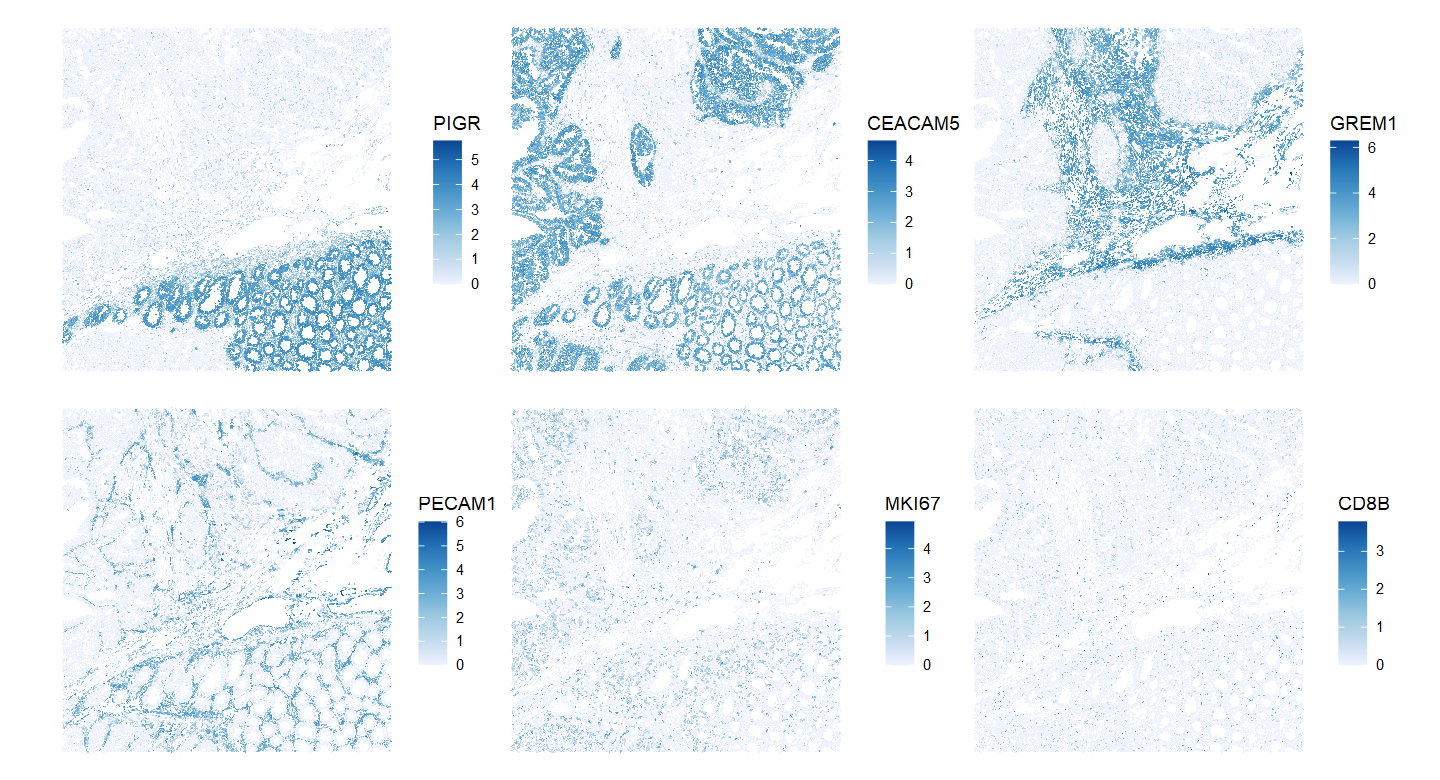

In [18]:
options(repr.plot.width = 12, repr.plot.height = 6.5)

plotSpatialFeature(
  sfe, 
  features = contrast_genes, 
  colGeometryName = "cellSeg", 
  ncol = 3
)

The cell-polygon topographies illustrate directly why spatial autocorrelation behaves as an _architectural gradient rather than a binary noise filter_. Across the top row, all three macro-compartment drivers form broad, homotypic multi-cellular zones: **`PIGR`** (I = 0.8118) exclusively rings the regular circular normal colonic crypts across the lower mucosa while sparing the far lower-left tumor lobule and the entire upper half; **`CEACAM5`** $I = 0.6655) illuminates both the lower mucosal crypts and the crowded invasive cribriform adenocarcinoma glands along the upper-left, upper-right, upper-center, and lower-left margins; and **`GREM1`** (I = 0.7628) forms the exact mesenchymal complement in the upper half, blanketing the reactive CAF stroma wrapping those malignant glands and sharpening the diagonal muscularis frontier beneath the dilated submucosal vessel.

Across the bottom row, progressively finer spatial geometries explain the stepwise drop in fixed-neighborhood Moran's $I$. **`PECAM1`** (I = 0.4199, despite ranking eighth in `bio` at 0.6306) traces delicate single-cell-wide capillary networks threading through the inter-crypt lamina propria honeycomb and upper desmoplastic stroma while lining the inner endothelial rim of the central submucosal vessel; because each endothelial cell is flanked by unrelated epithelial or fibroblastic neighbors, $k = 6$ averaging dilutes its local concordance. **`MKI67`** (I = 0.1730) highlights discrete proliferating nuclei concentrated along normal crypt rings and invasive tumor nests (particularly in the upper-right and left glands) while sparing the quiescent central stroma, and **`CD8B`** (I = 0.0198) pinpoints sparse, isolated cytotoxic T lymphocytes scattered individually across the lamina propria and peritumoral stroma—confirming visually that near-zero Moran's $I$ reflects dispersed single-cell biology rather than technical noise.

#### Multi-Scale Gaussian Process Validation (`nnSVG`)

While graph-based Moran's $I$ evaluates all 422 biological genes in under a minute, fitting multi-scale Nearest-Neighbor Gaussian Process (NNGP) models via [`nnSVG`](https://www.nature.com/articles/s41467-023-39748-z) requires per-gene maximum-likelihood optimization across all 47,671 single-cell coordinates—making a full 422-gene run prohibitively slow on a single workstation. As in the previous notebooks, we therefore evaluate `nnSVG` on a curated **10-gene benchmark panel** spanning all three empirical regimes surfaced above: macro-compartment drivers from the top-10 Moran's $I$ table (`PIGR`, `CEACAM5`, `GREM1`, `IGHG3`), high-variance focal and vascular drivers from the top-10 `bio` table (`HLA-DRA`, `PECAM1`) alongside intermediate proliferation landmark `MKI67`, and actively expressed dispersed targets from the bottom-5 active Moran's $I$ table (`CD8B`, `HDC`, `SFXN1`). This targeted benchmark tests whether adaptive spatial length scales ($l_g$) recover fine vascular and immune networks that fixed-$k$ Moran's $I$ attenuates.

In [19]:
# Define a 10-gene benchmark spanning macro-compartment, focal/vascular, and dispersed regimes
svg_benchmark_genes <- c(
  "PIGR", "CEACAM5", "GREM1", "IGHG3",
  "HLA-DRA", "PECAM1", "MKI67",
  "CD8B", "HDC", "SFXN1"
)

In [20]:
# Subset SFE to the 10-gene benchmark and fit NNGP models
sub <- sfe[svg_benchmark_genes, ]
set.seed(42)

sub <- nnSVG::nnSVG(
  sub, 
  BPPARAM = BiocParallel::SnowParam(workers = 4)  # Optional (on Windows)
)

Warning message in nnSVG::nnSVG(sub, BPPARAM = BiocParallel::SnowParam(workers = 4)):
"Rows (genes) and/or columns (spots) containing all zero counts have been found. Please see examples in tutorial for code to filter out zeros and/or low-expressed genes to avoid errors."
failed to open the port 11895, trying a new port...



In [21]:
# Transfer nnSVG statistics back into rowData(sfe)
nnsvg_cols <- c("LR_stat", "prop_sv", "padj")
rowData(sfe)[nnsvg_cols] <- NA_real_
rowData(sfe)[rownames(sub), nnsvg_cols] <- rowData(sub)[, nnsvg_cols]

In [22]:
# Compare bio variance, nnSVG effect sizes, and Moran's I side-by-side
rowData(sfe)[svg_benchmark_genes, ] |>
  as.data.frame() |>
  dplyr::select(bio, LR_stat, prop_sv, padj, dplyr::starts_with("moran_")) |>
  dplyr::arrange(dplyr::desc(LR_stat)) |>
  signif(4)

,bio,LR_stat,prop_sv,padj,moran_sample01
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PIGR,0.71700,75930.00,0.849700,0.000e+00,0.81180
GREM1,0.77490,69680.00,0.878600,0.000e+00,0.76280
IGHG3,0.79190,51160.00,0.718900,0.000e+00,0.66140
CEACAM5,0.30580,49290.00,0.724300,0.000e+00,0.66550
HLA-DRA,0.81390,26340.00,0.647400,0.000e+00,0.44080
PECAM1,0.63180,24320.00,0.606700,0.000e+00,0.41990
MKI67,0.05984,5449.00,0.228000,0.000e+00,0.17300
CD8B,0.03558,108.30,0.012990,0.000e+00,0.01979
HDC,0.08109,65.63,0.038240,6.291e-15,0.01460


At the top of the hierarchy, macro-compartment markers command `LR_stat` = 49,290–75,930 and `prop_sv` = 0.7189–0.8786, with `GREM1` achieving the highest spatial variance fraction (`prop_sv` = 0.8786) ahead of `PIGR` (0.8497). Crucially, whereas fixed-$k$ Moran's $I$ dropped `HLA-DRA` (0.4408) and `PECAM1` (0.4199) substantially below `CEACAM5` (0.6655)—not because they are rarer, but because they trace fine, 1-cell-wide branching networks across both stroma and lamina propria rather than thick epithelial sheets—`nnSVG` adapts its spatial kernel length scale ($l_g$) per gene and recovers **64.7% and 60.7% spatial variance** (`prop_sv` = 0.6474 and 0.6067), nearly matching macro-compartment epithelial markers.

At the opposite end, `MKI67` occupies an intermediate focal regime (`LR_stat` = 5,449, `prop_sv` = 0.2280), while dispersed single-cell targets (`CD8B`, `HDC`, `SFXN1`) collapse by two to three orders of magnitude in `LR_stat` (29.16–108.3) and explain just **0.65%–3.82%** of total variance spatially (`prop_sv` = 0.0065–0.0382), mirroring their near-zero Moran's $I$ (0.0107–0.0198). Yet because our ROI contains **47,671 cells**, even `SFXN1` with less than 1% spatial variance yields `padj` $= 4.661 \times 10^{-7}$ (and `CD8B` reaches `padj` $= 0$). Prioritizing spatial patterns by effect size (`prop_sv`, `LR_stat`, or full-panel `moran_sample01`) rather than P-values remains essential—while keeping all 422 biological genes in PCA so dispersed immune subsets like `CD8B`+ T cells and `HDC`+ mast cells remain cleanly resolvable.

## Dimensionality reduction

### Standard Principal Component Analysis (PCA) on all 422 biological genes (λ = 0)

Having verified that our 422 curated biological targets separate from the 93 active negative controls across both `bio` variance and spatial autocorrelation, we compute standard unconstrained **PCA** (`scater::runPCA()`) directly on `logcounts` restricted strictly to `is_bio`. As established in the previous notebooks, we keep `scale = FALSE` (mean-centering genes without dividing by standard deviation) so dominant lineage markers retain their natural covariance weighting; scaling to unit variance would artificially inflate ultra-low-abundance panel targets (such as patient-absent TCR clonotypes or rare `CD7`+ cells) to the same weight as `IGFBP7`, `HLA-DRA`, or `PIGR`.

#### Scree Diagnostics & Dimension Selection

In [23]:
# Compute 30 standard PCs directly on all 422 curated biological genes
set.seed(42)
sfe <- runPCA(
  sfe, 
  ncomponents = 30, 
  subset_row = rowData(sfe)[["is_bio"]],   # Excluding 93 negative controls
  exprs_values = "logcounts", 
  scale = FALSE, 
  name = "PCA"
)

In [24]:
# Extract % variance explained and construct scree data frame
percent_var <- attr(reducedDim(sfe, "PCA"), "percentVar")

pca_scree_df <- data.frame(
  PC = seq_along(percent_var), 
  VarianceExplained = percent_var, 
  CumulativeVariance = cumsum(percent_var)
)

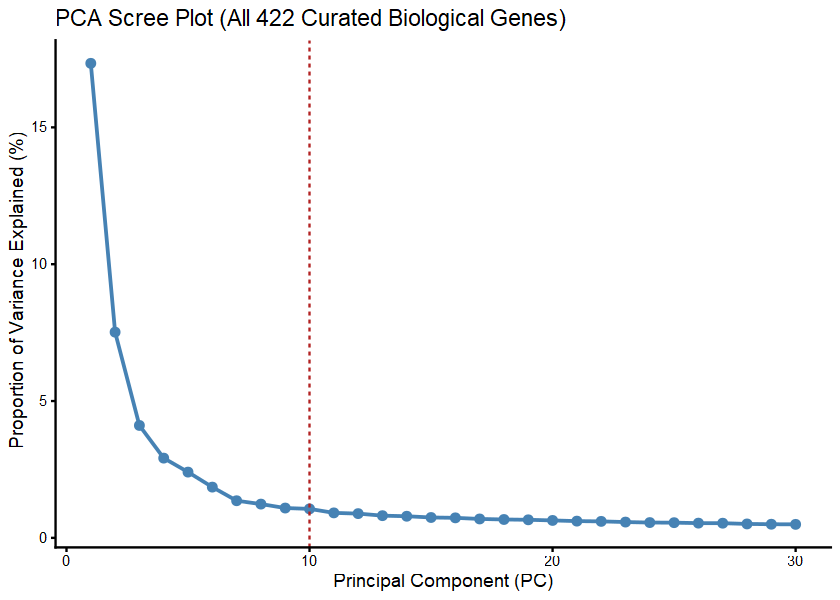

In [25]:
options(repr.plot.width = 7, repr.plot.height = 5)

ggplot(pca_scree_df, aes(x = PC, y = VarianceExplained)) +
  geom_point(color = "steelblue", size = 2) +
  geom_line(color = "steelblue", linewidth = 0.8) +
  geom_vline(xintercept = 10, linetype = "dashed", color = "firebrick") +
  theme_classic() +
  labs(
    title = "PCA Scree Plot (All 422 Curated Biological Genes)", 
    x     = "Principal Component (PC)", 
    y     = "Proportion of Variance Explained (%)"
  )

Because Xenium's 422-gene panel eliminates the uninformative housekeeping tail that inflates total variance in whole-transcriptome assays—and benefits from lower per-gene Poisson dropout than shallow sequencing capture—variance concentrates sharply in the leading axes compared with segmented Visium HD in the previous notebooks. `PC1` captures **17.34%** of total panel variance (nearly double the ≈ 9.4% seen in segmented Visium HD) and `PC2` accounts for **7.52%**, followed by a steep drop through `PC3` (**4.11%**) and a gentler bend across `PC4`–`PC7`. From `PC8`–`PC10`, the curve flattens into a smooth asymptotic tail below **1%** per component (`PC11` onward). Retaining the top **10 PCs** (`n_dimred` = 10) captures **40.88%** of cumulative panel variance—preserving both major colorectal lineages and minor immune or vascular subpopulations while maintaining direct parity with our Visium HD pipelines.

#### Spatial Projection & Gene Loadings

We now project `PC1`–`PC4` onto cell `centroids` using `Voyager::spatialReducedDim()` with zero-centered diverging colors (`divergent = TRUE`, `diverge_center = 0`) and extract the gene eigenvector loadings (`rotation`) driving `PC1` and `PC2`.

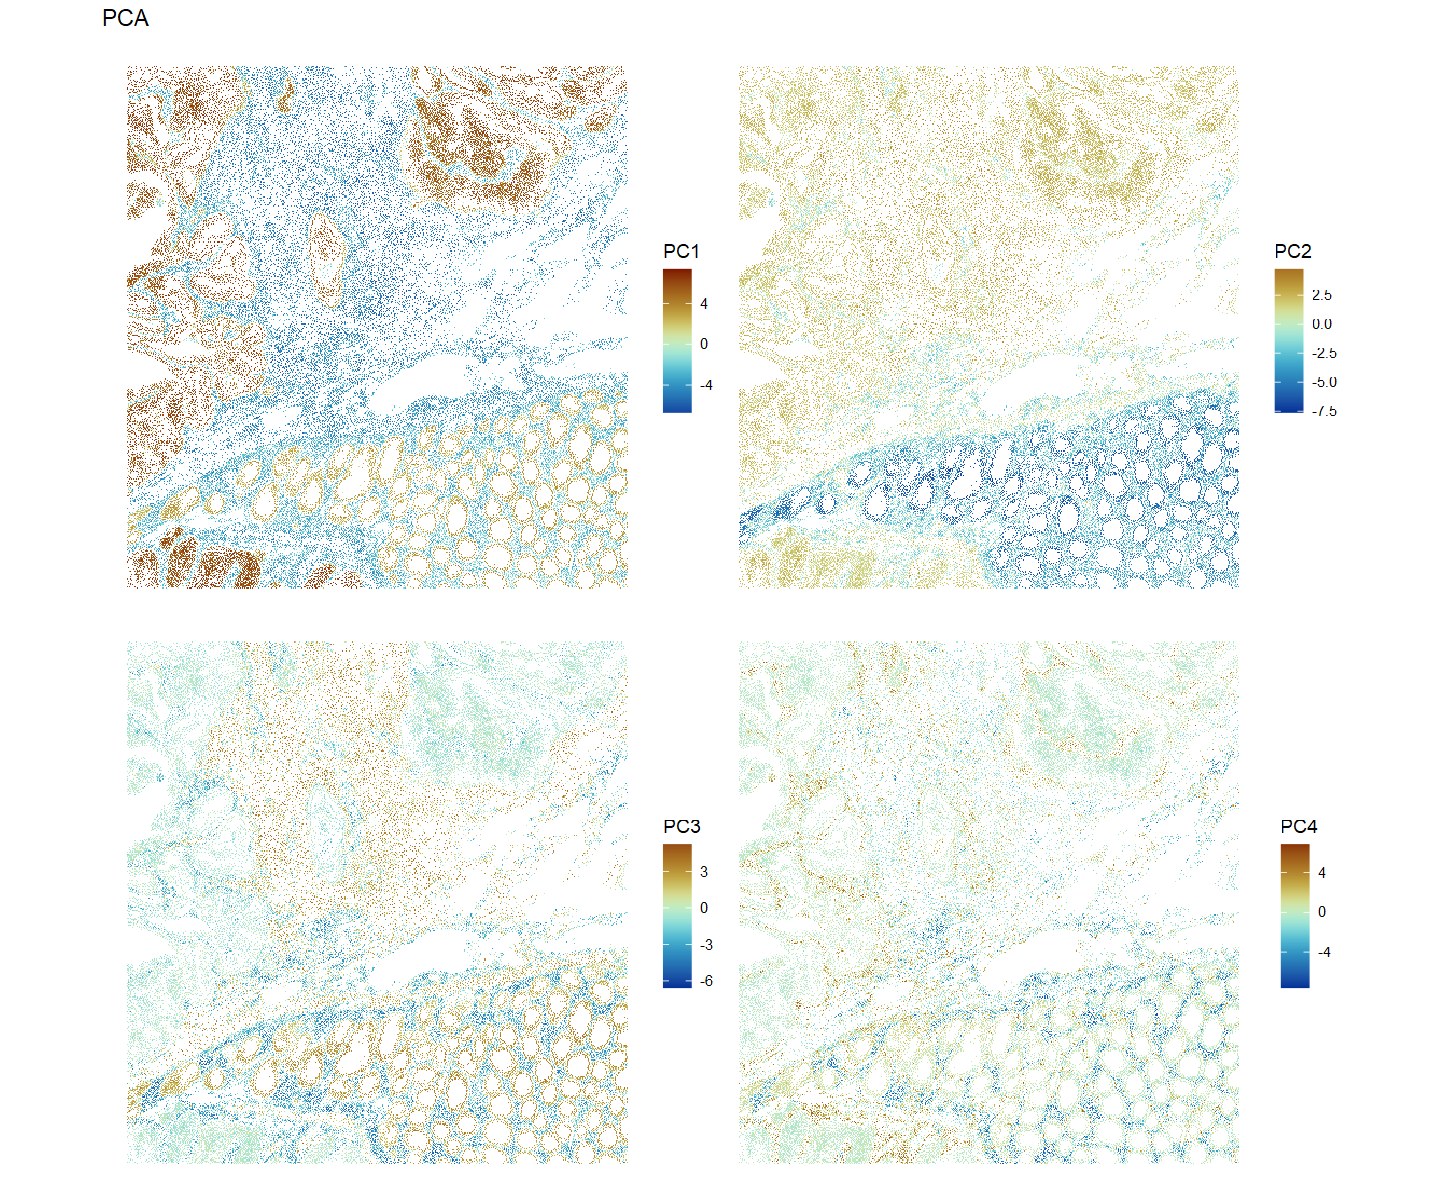

In [26]:
# Project top 4 standard PCs onto cell centroids
options(repr.plot.width = 12, repr.plot.height = 10)

spatialReducedDim(
  sfe, 
  dimred = "PCA", 
  ncomponents = 4, 
  colGeometryName = "centroids", 
  scattermore = TRUE, 
  divergent = TRUE, 
  diverge_center = 0
)

In [27]:
# Extract the 422 x 30 rotation (loadings) matrix and inspect signed top 10 drivers of PC1 & PC2
pca_rot <- attr(reducedDim(sfe, "PCA"), "rotation")

lapply(c("PC1", "PC2"), function(pc) {
  pca_rot[, pc] |>
    abs() |>
    sort(decreasing = TRUE) |>
    names() |>
    head(n = 10)
}) |> setNames(c("PC1", "PC2"))

$PC1
 [1] "CEACAM6" "GPX2"    "MMP2"    "IGFBP7"  "CD24"    "CEACAM5" "GREM1"  
 [8] "TAGLN"   "FERMT1"  "MYC"    

$PC2
 [1] "PIGR"    "THBS1"   "OLFM4"   "PRSS23"  "CLCA1"   "DAB2"    "TIMP3"  
 [8] "LCN2"    "CEACAM6" "GREM1"

Even without spatial coordinates as inputs, unconstrained PCA (λ = 0) across all 422 biological genes reconstructs the colorectal adenocarcinoma architecture, and resolves a key lineage ambiguity earlier than whole-transcriptome Visium HD. Along **`PC1`** (17.34% variance), positive brown scores (+2 → +7) unite **all epithelial compartments**—both the intensely stained lobulated invasive adenocarcinoma nests (upper-left, upper-right, upper-center, and far lower-left corner) and the regular circular normal colonic crypts across the lower-right mucosa—driven by epithelial and carcinoma markers (`CEACAM6`, `GPX2`, `CD24`, `CEACAM5`, `FERMT1`, `MYC`). Opposing negative blue scores (-2 → -7) blanket the intervening **desmoplastic stroma** and inter-crypt lamina propria, commanded by mesenchymal, CAF, and smooth-muscle drivers (`MMP2`, `IGFBP7`, `GREM1`, `TAGLN`).

Whereas whole-transcriptome Visium HD grouped normal crypt epithelium and invasive adenocarcinoma together across `PC1` × `PC2`, Xenium's curated CRC panel separates them immediately along **`PC2`** (7.52% variance). Deep blue negative scores (-2.5 → -7.5) sharply isolate the **normal colonic crypts** across the lower-right mucosa—stopping cleanly at the boundary of the lower-left tumor lobule—anchored by mucosal differentiation and crypt-stem markers (`PIGR`, `OLFM4`, `CLCA1`, `LCN2`). Conversely, warm tan and brown scores (+1 → +4.5) span both the **invasive carcinoma glands** (including the lower-left lobule) and **reactive desmoplastic stroma** above, driven by `THBS1`, `PRSS23`, `DAB2`, `TIMP3`, `CEACAM6`, and `GREM1`. Beyond these two dominant axes, **`PC3`** (4.11%) highlights contrasting sub-regions across the central stroma and crypt rims (brown) versus the upper-right tumor nests and lower-left muscularis/lamina propria bands (blue), while **`PC4`** (2.91%) captures finer localized streaks along the muscularis interface alongside noticeable cell-to-cell speckle caused by evaluating each cell independently of its physical neighbors.

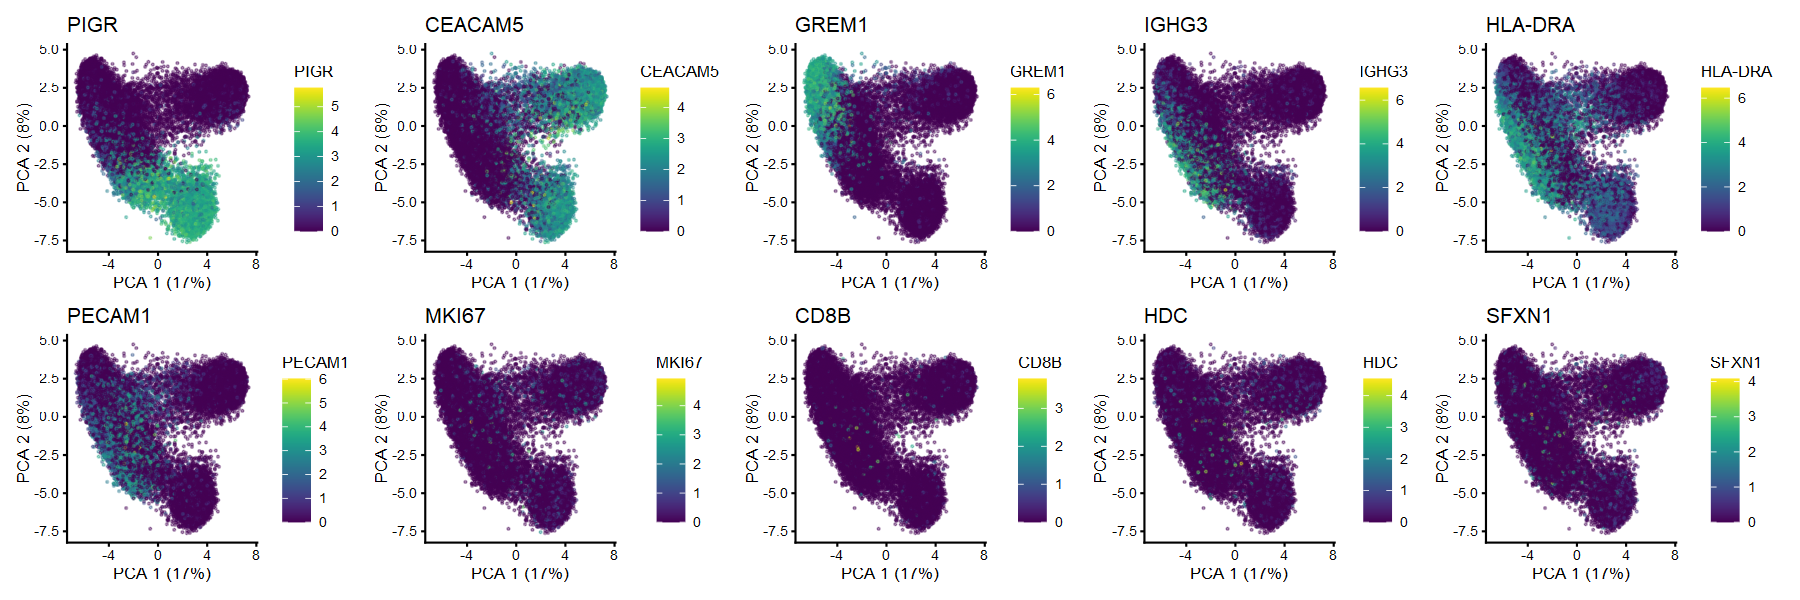

In [28]:
# Project the 10 benchmark genes onto the 2D standard PCA (PC1 x PC2) space
pca_plots <- lapply(svg_benchmark_genes, function(gene) {
  plotReducedDim(
    sfe, 
    dimred = "PCA", 
    colour_by = gene, 
    point_size = 0.2, 
    point_alpha = 0.4 
  ) +
    labs(title = gene, color = NULL) +
    theme_classic(base_size = 10)
})

options(repr.plot.width = 15, repr.plot.height = 5)
wrap_plots(pca_plots, ncol = 5)

Projecting our 10 benchmark genes onto the `PCA 1` (17%) × `PCA 2` (8%) plane reveals a **C-shaped, three-lobe manifold** that contrasts sharply with the triangular 2-simplex observed in whole-transcriptome Visium HD. Whereas Visium HD collapsed normal mucosa and invasive carcinoma onto the same epithelial vertex, Xenium's curated panel resolves **two distinct right-hand epithelial lobes** separated along `PCA 2`: an **upper-right invasive adenocarcinoma lobe** (`PCA 1` ≈ +2 to +6, `PCA 2` ≈ +2.5) strongly enriched for `CEACAM5` and negative for `PIGR`, and a **bottom-right normal colonic crypt lobe** (`PCA 1` ≈ +2 to +5, `PCA 2` ≈ -5.0) intensely positive for `PIGR` alongside moderate `CEACAM5`—mirroring their dual tissue distribution while keeping normal and malignant epithelium separated in 2D space.

On the opposite side (`PCA 1` < 0), non-epithelial lineages form a **continuous left-hand mesenchymal and immune spine** rather than a single isolated vertex. Reactive **`GREM1`**⁺ CAFs anchor the far upper-left edge (`PCA 1` ≈ -6 to -4, `PCA 2` ≈ +1 to +4), **`PECAM1`**⁺ vascular endothelia occupy the inner-left band (`PCA 1` ≈ -4 to -1, `PCA 2` ≈ -3 to +2), and **`IGHG3`**⁺ IgG plasma cells sweep along the lower-left outer rim (`PCA 1` ≈ -5 to -1, `PCA 2` ≈ -5 to 0). Notably, **`HLA-DRA`** co-localizes across several of these zones in `PCA 1` × `PCA 2` space: it overlaps **`IGHG3`** along the lower-left mucosal lamina propria rim (marking MHC class II-positive macrophages, dendritic cells, and B cells), extends across the mid-left **`PECAM1`**⁺ endothelial/perivascular band (reflecting perivascular myeloid infiltrates and endothelial MHC-II expression), and even shows faint teal signal within both epithelial lobes. Because `PCA 1` and `PCA 2` together capture only ≈ 25% of panel variance, these distinct non-epithelial lineages partially project onto overlapping coordinates along the left spine—just as **`MKI67`**⁺ proliferating cells scatter across both epithelial lobes while **`CD8B`**⁺ T cells, **`HDC`**⁺ mast cells, and **`SFXN1`** appear as sparse speckles—underscoring why deeper components (`PC3`–`PC10`) and spatially-aware **BANKSY** embeddings are required to cleanly resolve intermingled cell types and tissue domains.

### Dual-regime BANKSY: cell-type assignment (λ = 0.2) vs. domain segmentation (λ = 0.8)

Unlike 16-µm binned Visium HD—where physical grid averaging blends adjacent cells—and even sharper than segmented Visium HD—where array-based permeabilization introduces minor lateral mRNA diffusion across cell margins—Xenium's diffraction-limited optical decoding operates at **true single-cell resolution**. This fidelity allows **BANKSY** to pair definitive cell-type markers with crisp neighborhood geometry over a $k = 20$ nearest-neighbor graph:

$$
\mathbf{b}_i = \begin{bmatrix} \sqrt{1 - \lambda} \cdot \mathbf{x}_i \\ \sqrt{\lambda} \cdot \bar{\mathbf{x}}_i \end{bmatrix} \in \mathbb{R}^{2 \times 422 \ (= 844)}
$$

By passing `lambda = c(0.2, 0.8)` to `Banksy::runBanksyPCA()`, we generate _two complementary spatio-molecular embeddings_ from the same neighborhood mean matrix $\bar{\mathbf{x}}_i$:

* **Cell-Type Assignment (λ = 0.2):** Weights each cell's intrinsic transcriptome by $\sqrt{0.8} \approx 0.894$ against $\sqrt{0.2} \approx 0.447$ for its neighborhood average (a **2:1 intrinsic-to-neighborhood ratio**). This gentle spatial regularization suppresses single-cell dropout noise while keeping intermingled immune, endothelial, and stromal populations (`CD8B`+ T cells, `PECAM1`+ capillaries, `HLA-DRA`+ macrophages, `GREM1`+ CAFs) sharply separated from neighboring epithelial cells.
* **Tissue Domain Segmentation (λ = 0.8):** Inverts the weighting to $\sqrt{0.2} \approx 0.447$ intrinsic versus $\sqrt{0.8} \approx 0.894$ neighborhood average (a **1:2 intrinsic-to-neighborhood ratio**). By grouping cells primarily according to *who their neighbors are*, high-$\lambda$ BANKSY compensates for the 422-gene panel limit by maximizing spatial context—uniting co-resident lineages into continuous histological niches (normal colonic mucosa, invasive adenocarcinoma bed, reactive desmoplastic stroma, and muscularis interface).

We compute both 10-component embeddings in a single workflow and register them into `sfe` as `"PCA_banksy_lam02"` and `"PCA_banksy_lam08"`.

In [29]:
# Define BANKSY neighborhood size and dual spatial mixing weights
k_geom <- 20
lambda_weights <- c(0.2, 0.8)
xy_coords <- spatialCoordsNames(sfe)

# Compute k = 20 neighborhood expression averages across all 422 biological genes
set.seed(42)
sfe_banksy <- computeBanksy(
  sfe[rowData(sfe)[["is_bio"]], ], 
  assay_name = "logcounts", 
  coord_names = xy_coords, 
  k_geom = k_geom
)

Computing neighbors...

Spatial mode is kNN_median

Parameters: k_geom=20

Done

Done



In [30]:
# Compute 10 spatio-molecular PCs under both lambda regimes simultaneously
set.seed(42)
sfe_banksy <- runBanksyPCA(
  sfe_banksy, 
  lambda = lambda_weights, 
  npcs = 10
)

In [31]:
# Verify generated BANKSY slot names and register both into primary sfe container
reducedDimNames(sfe_banksy)
reducedDim(sfe, "PCA_banksy_lam02") <- reducedDim(sfe_banksy, "PCA_M0_lam0.2")
reducedDim(sfe, "PCA_banksy_lam08") <- reducedDim(sfe_banksy, "PCA_M0_lam0.8")
rm(sfe_banksy)

reducedDimNames(sfe)

[1] "PCA"           "PCA_M0_lam0.2" "PCA_M0_lam0.8"

[1] "PCA"              "PCA_banksy_lam02" "PCA_banksy_lam08"

#### Spatial Projections Across λ = 0.2 and λ = 0.8

We project `PC1`–`PC4` onto cell `centroids` for both `PCA_banksy_lam02` and `PCA_banksy_lam08` to observe directly how shifting λ from 0.2 to 0.8 transitions the representation from single-cell typing to macro-anatomical domain segmentation.

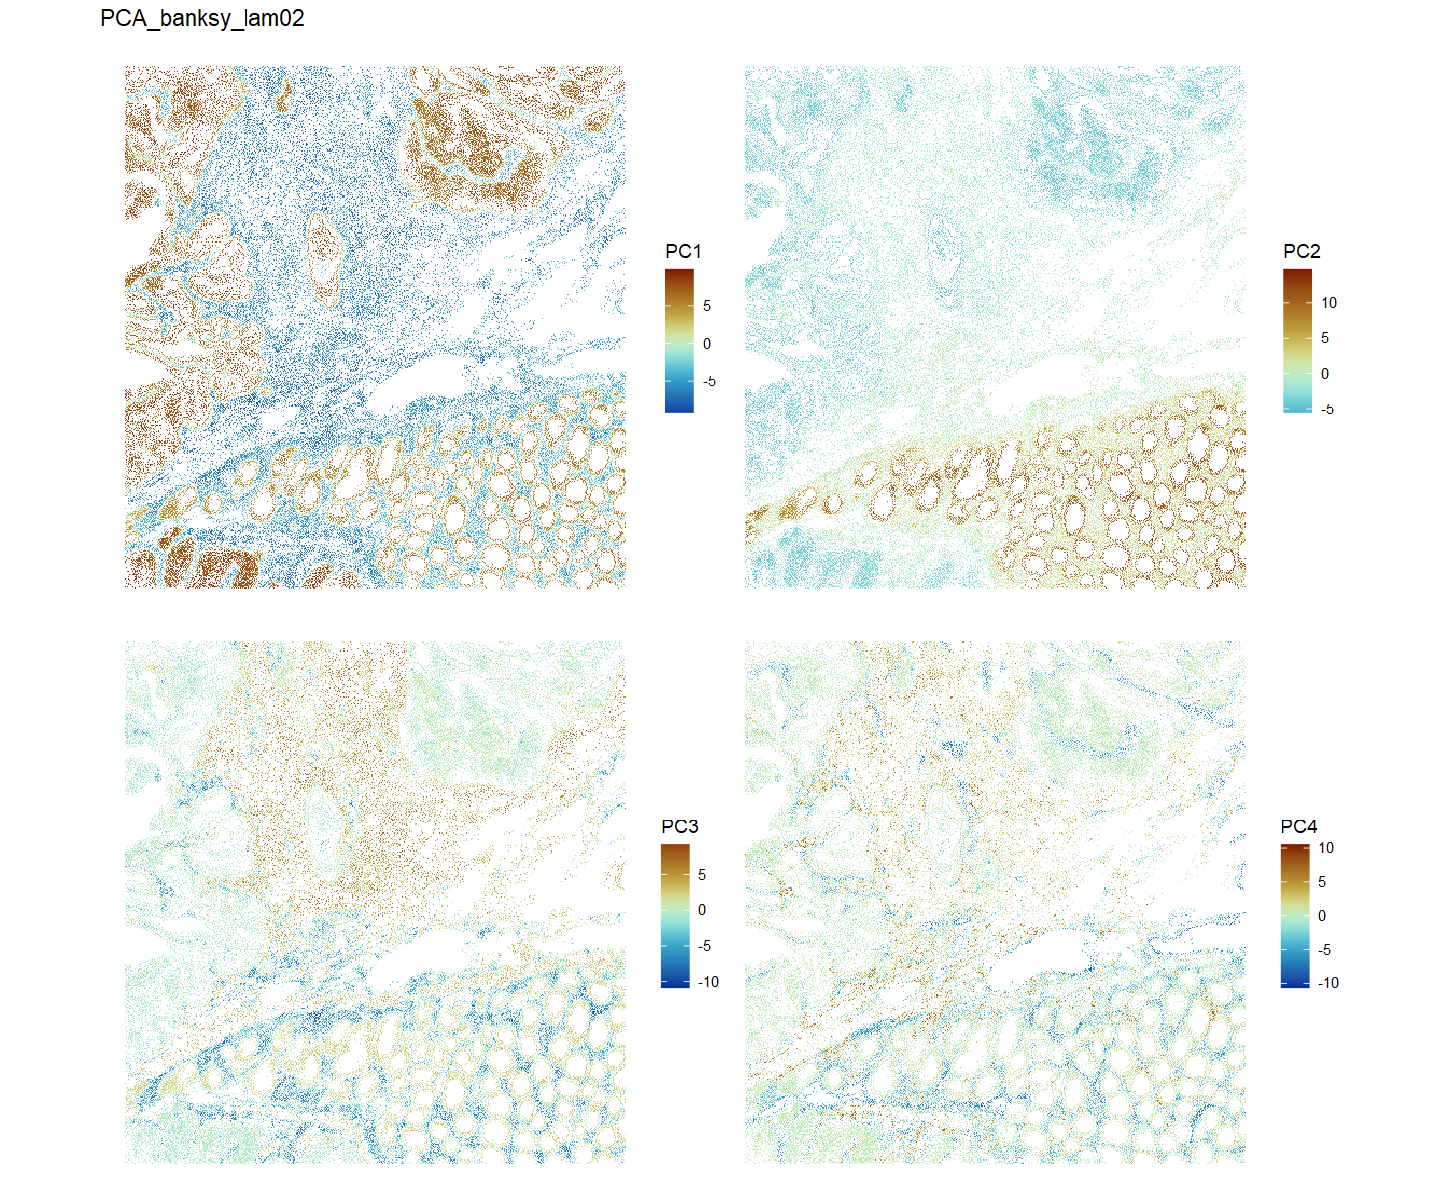

In [32]:
# Spatial map of top 4 PCs under Cell-Type Assignment regime (lambda = 0.2)
options(repr.plot.width = 12, repr.plot.height = 10)

Voyager::spatialReducedDim(
  sfe, 
  dimred = "PCA_banksy_lam02", 
  ncomponents = 4, 
  colGeometryName = "centroids", 
  scattermore = TRUE, 
  divergent = TRUE, 
  diverge_center = 0
)

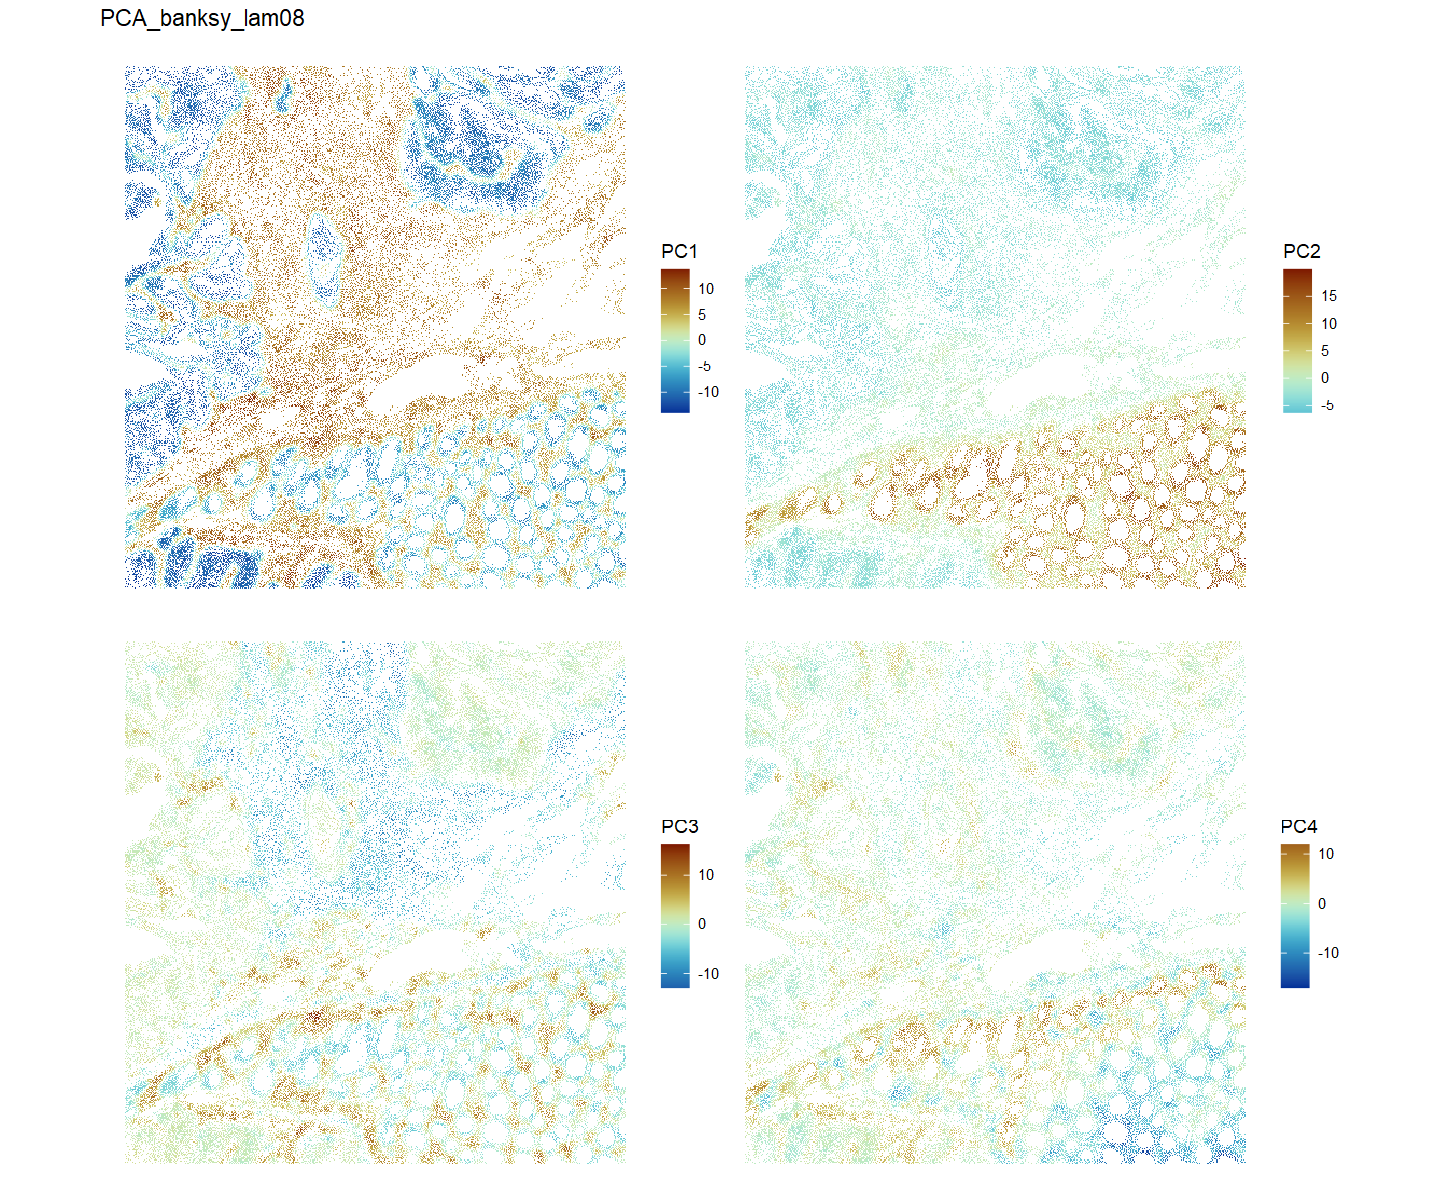

In [33]:
# Spatial map of top 4 PCs under Tissue Domain Segmentation regime (lambda = 0.8)
options(repr.plot.width = 12, repr.plot.height = 10)

Voyager::spatialReducedDim(
  sfe, 
  dimred = "PCA_banksy_lam08", 
  ncomponents = 4, 
  colGeometryName = "centroids", 
  scattermore = TRUE, 
  divergent = TRUE, 
  diverge_center = 0
)

Comparing the three spatial PC projections sequentially—from standard `PCA` (λ = 0) to `PCA_banksy_lam02` (λ = 0.2) and `PCA_banksy_lam08` (λ = 0.8)—cleanly separates trivial ±1 eigenvector sign flips from genuine neighborhood-driven reorganization. Stepping from λ = 0 to **λ = 0.2** preserves the overall structure of `PC1` while slightly darkening brown epithelial scores inside the normal crypts as 20-NN regularization reduces single-cell dropout speckle; `PC2` undergoes a direct color reversal that flips the normal mucosal crypts from deep blue (-7.5) to rich brown (+13) while keeping inter-crypt lamina propria corridors distinct; `PC3` retains its upper-stroma-versus-mucosa polarity with noticeably darker blue contrast (-10 vs. -6) across the normal tissue; and `PC4` resolves darker, sharper focal streaks within the upper tumor stroma.

Increasing neighborhood mixing from λ = 0.2 to **λ = 0.8** shifts the embedding from single-cell denoising to macro-anatomical domain segmentation. Both `PC1` and `PC3` reverse polarity while smoothing away cell-to-cell granularity: `PC1` flips the desmoplastic stroma, muscularis mucosae, and lamina propria into a unified brown mesenchymal scaffold (+12) framing deep-blue invasive carcinoma nests (-12), while `PC3` flips the upper-central stroma to cool blue (-10) against a warm-brown mucosal–muscularis ribbon (+15). By contrast, `PC2` remains nearly identical in spatial pattern—only slightly smoother and reaching higher amplitude (+18 vs. +13) across the normal colonic mucosa—whereas `PC4` undergoes a clear structural shift, abandoning fine upper-stromal streaks to partition the **normal mucosal region** into a deep-blue lower-right crypt sub-zone (-15) and a warm-brown upper mucosal band (+10) bordering the muscularis interface.

In [34]:
# Compute component variances (eigenvalues) across PC1-PC10 for both BANKSY regimes
banksy_var_02 <- apply(reducedDim(sfe, "PCA_banksy_lam02"), 2, var)
banksy_var_08 <- apply(reducedDim(sfe, "PCA_banksy_lam08"), 2, var)

banksy_scree_df <- rbind(
  data.frame(PC = 1:10, Variance = banksy_var_02, Regime = "Cell Typing (λ = 0.2)"),
  data.frame(PC = 1:10, Variance = banksy_var_08, Regime = "Domain Segmentation (λ = 0.8)")
)

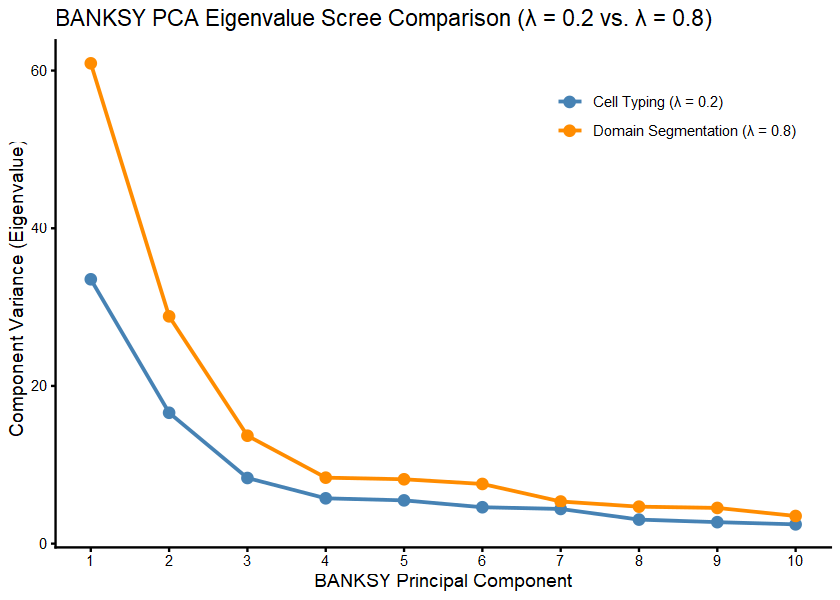

In [35]:
options(repr.plot.width = 7, repr.plot.height = 5)

ggplot(banksy_scree_df, aes(x = PC, y = Variance, color = Regime)) +
  geom_point(size = 2.5) +
  geom_line(linewidth = 0.8) +
  scale_x_continuous(breaks = 1:10) +
  scale_color_manual(
    values = c("Cell Typing (λ = 0.2)" = "steelblue", "Domain Segmentation (λ = 0.8)" = "darkorange")
  ) +
  theme_classic() +
  labs(
    title = "BANKSY PCA Eigenvalue Scree Comparison (λ = 0.2 vs. λ = 0.8)",
    x     = "BANKSY Principal Component",
    y     = "Component Variance (Eigenvalue)",
    color = NULL
  ) +
  theme(
    legend.position = c(0.8, 0.85))

Because neighborhood averaging suppresses uncorrelated single-cell shot noise while reinforcing spatially concordant gene co-expression across adjacent cells, increasing λ from 0.2 to 0.8 roughly doubles the leading eigenvalues (`PC1`: 33.53 → 60.92; `PC2`: 16.60 → 28.83; `PC3`: 8.32 → 13.69; `PC4`: 5.75 → 8.37) across the steep macro-domain axes before both curves flatten across `PC4`–`PC6` and converge toward a shallow tail across `PC7`–`PC10`.

### Three-way UMAP manifold comparison (λ = 0 vs. λ = 0.2 vs. λ = 0.8)

To synthesize the same 10-dimensional latent space across all three regimes, we compute 2D **UMAP** embeddings from the top 10 principal components of each embedding (`n_dimred` = 10 from the 30-PC standard `PCA`, and all 10 stored components from `PCA_banksy_lam02` and `PCA_banksy_lam08`). Coloring all three manifolds by biological gene complexity verifies that complexity gradients remain smooth without fracturing into depth-driven technical artifacts.

In [36]:
# Verify biological gene complexity range (nGenes) before coloring UMAPs
summary(sfe[["nGenes"]])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   5.00   35.00   49.00   52.07   66.00  199.00 

In [37]:
# Compute UMAP across all three 10-dimensional PCA embeddings
set.seed(42)
sfe <- runUMAP(sfe, dimred = "PCA", n_dimred = 10, name = "UMAP")

In [38]:
set.seed(42)
sfe <- runUMAP(sfe, dimred = "PCA_banksy_lam02", name = "UMAP_banksy_lam02")

In [39]:
set.seed(42)
sfe <- runUMAP(sfe, dimred = "PCA_banksy_lam08", name = "UMAP_banksy_lam08")

In [40]:
# Helper to render UMAP manifolds consistently colored by biological detected genes (nGenes)
make_umap_plot <- function(dimred_name, title_text) {
  plotReducedDim(
    sfe, 
    dimred = dimred_name, 
    colour_by = "nGenes", 
    point_size = 0.2, 
    point_alpha = 0.45 
  ) +
    scale_color_gradientn(colors = jet(), trans = "log10") +
    labs(title = title_text, color = "Detected\nGenes") +
    theme_classic()
}

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


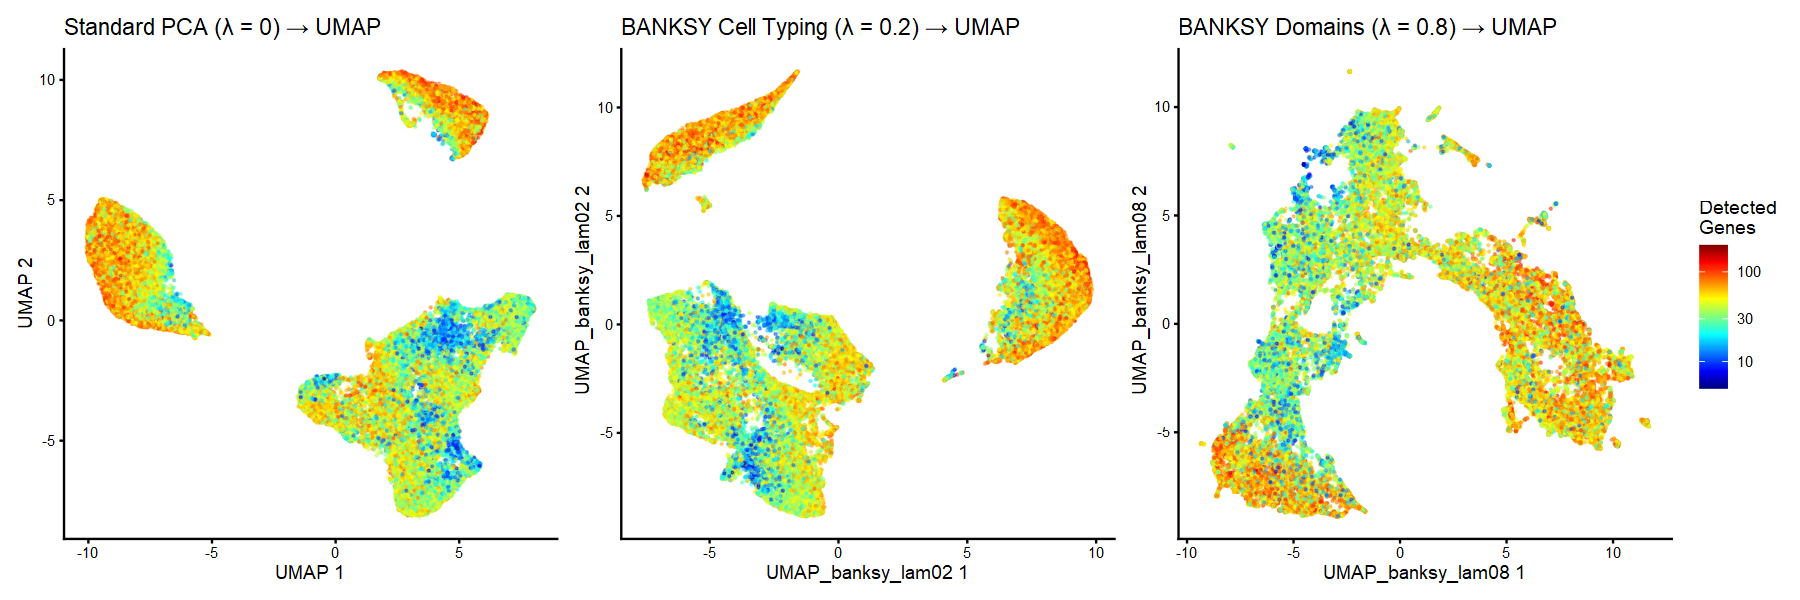

In [41]:
options(repr.plot.width = 15, repr.plot.height = 5)

p_u0 <- make_umap_plot("UMAP", "Standard PCA (λ = 0) → UMAP")
p_u2 <- make_umap_plot("UMAP_banksy_lam02", "BANKSY Cell Typing (λ = 0.2) → UMAP")
p_u8 <- make_umap_plot("UMAP_banksy_lam08", "BANKSY Domains (λ = 0.8) → UMAP")

(p_u0 | p_u2 | p_u8) + plot_layout(guides = "collect")

Viewing the three UMAP manifolds side-by-side connects Xenium's single-cell resolution directly to our earlier Visium HD embeddings. Under **standard PCA (λ = 0, left)**, the 47,671 cells split into three completely disconnected islands—two high-complexity epithelial islands (`nGenes` ≈ 60–199, orange/red) corresponding to invasive carcinoma and normal crypt epithelium, alongside a large lower-right mesenchymal and immune body (`nGenes` ≈ 5–60, blue/cyan/green/yellow). Introducing gentle neighborhood regularization at **λ = 0.2 (middle)** preserves this same three-island topology—because true single-cell optical decoding lacks the partial-volume bin mixing of 16-µm grids and low λ respects sharp cell-type boundaries—while carving crisp internal clefts and sub-lobes inside the mesenchymal–immune mainland to sharpen endothelial, fibroblast, macrophage, and plasma-cell lineages for downstream **cell-type assignment**.

Raising neighborhood mixing to **λ = 0.8 (right)** transforms those disconnected cell-type islands into the **connected tri-lobed domain architecture** observed previously in 16-µm binned Visium HD (`UMAP_banksy` in the previous notebook). Because cells are now grouped primarily according to who their physical neighbors are, the two high-complexity epithelial compartments (lower-left and far-right arms, orange/red) remain distinct at opposite poles while bridging continuously through the upper lower-complexity stromal, lamina propria, and muscularis-interface arm—mirroring the physical spatial transitions of the CRC tissue section for downstream **spatial domain segmentation**.

## Finalization

We serialize the enriched `SpatialFeatureExperiment` object—containing our biological feature mask (`is_bio`), variance metrics (`bio`), full-panel spatial autocorrelation (`moran_sample01`), benchmark `nnSVG` statistics (`LR_stat`, `prop_sv`, `padj`), spatial neighbor graph (`knn6`), and all six reduced-dimension embeddings (`PCA`, `PCA_banksy_lam02`, `PCA_banksy_lam08`, `UMAP`, `UMAP_banksy_lam02`, `UMAP_banksy_lam08`)—to `output/sfe_xenium_dimred` using `alabaster.sfe::saveObject()`.

In [42]:
# Verify final container slots and dimensions
sfe

class: SpatialFeatureExperiment 
dim: 515 47671 
metadata(1): Samples
assays(2): counts logcounts
rownames(515): ABCC8 ACP5 ... UnassignedCodeword_0292
  UnassignedCodeword_0298
rowData names(17): ID Symbol ... prop_sv padj
colnames(47671): ablhnkec-1 ablhpkkh-1 ... oikdllpb-1 oikeebja-1
colData names(40): transcript_counts control_probe_counts ... qc_keep
  sizeFactor
reducedDimNames(6): PCA PCA_banksy_lam02 ... UMAP_banksy_lam02
  UMAP_banksy_lam08
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : x_centroid y_centroid
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (MULTIPOLYGON), nucSeg (MULTIPOLYGON) 

Graphs:
sample01: col: knn6

Preserving all three 10-PC representations equips downstream clustering with a complete analytical suite: **`PCA_banksy_lam02`** (λ = 0.2) for noise-regularized single-cell-type clustering, **`PCA_banksy_lam08`** (λ = 0.8) for spatial tissue domain segmentation, and standard **`PCA`** (λ = 0) as the pure non-spatial reference baseline.

In [43]:
# Define standardized output directory
output_dir <- "output/sfe_xenium_dimred"

# Replace existing directory cleanly if present
if (dir.exists(output_dir)) {
  unlink(output_dir, recursive = TRUE)
}

# Serialize enriched SFE object
saveObject(sfe, output_dir)

# Verify directory creation
fs::dir_tree(output_dir)

>>> Saving SpatialExperiment

>>> Saving colgeometries

>>> Saving spatial graphs



output/sfe_xenium_dimred
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   ├── 1
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── reduced_dimensions
│   ├── 0
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   ├── OBJECT
│   │   │   └── other_contents
│   │   │       └── 0
│   │   │           ├── array.h5
│   │   │           └── OBJECT
│   │   └── OBJECT
│   ├── 1
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   └── OBJECT
│   │   └── OBJECT
│   ├── 2
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_cont

We clear the workspace and trigger garbage collection to release several gigabytes of spatial polygon geometries and count matrices from memory before opening the next module.

In [44]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,13893771,742.1,23610017,1261.0,23610017,1261.0
Vcells,43324144,330.6,128811552,982.8,251570125,1919.4
